# Análisis No Supervisado del Dataset Iris

análisis exploratorio y aplica técnicas de aprendizaje no supervisado sobre el dataset Iris para segmentar muestras, reducir dimensionalidad y detectar anomalías.

### 1. Carga y exploración del dataset
Se carga el dataset Iris y se muestran las primeras 5 filas y el resumen estadístico.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print('Primeras 5 filas:')
display(df.head())
print('Resumen estadístico:')
display(df.describe())

Primeras 5 filas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Resumen estadístico:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 2. Limpieza y preprocesamiento
Revisión de valores faltantes o atípicos, imputación/eliminación y normalización de datos numéricos.

In [2]:
# Revisar valores faltantes
print('Valores faltantes por columna:')
print(df.isnull().sum())

# Ejemplo de imputación: rellenar valores faltantes con la mediana de cada columna
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
print('Primeras filas tras imputación:')
display(df_imputed.head())

# También puedes eliminar filas con valores faltantes si lo prefieres
df = df.dropna()

# Revisión y tratamiento de valores atípicos (outliers) usando el método IQR
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
# Filtrar filas fuera de 1.5*IQR
df_outlier_filtered = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]
print(f'Se eliminaron {len(df) - len(df_outlier_filtered)} filas por valores atípicos.')
df = df_outlier_filtered

# Normalizar datos numéricos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
print('Datos normalizados. Primeras filas:')
display(pd.DataFrame(X_scaled, columns=df.columns).head())

Valores faltantes por columna:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64
Primeras filas tras imputación:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Se eliminaron 4 filas por valores atípicos.
Datos normalizados. Primeras filas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.910515,1.159151,-1.373764,-1.348525
1,-1.151122,-0.101922,-1.373764,-1.348525
2,-1.391729,0.402507,-1.430841,-1.348525
3,-1.512032,0.150292,-1.316687,-1.348525
4,-1.030819,1.411365,-1.373764,-1.348525


### 3. Clusterización con K-Means (k=3)
Se aplica K-Means y se visualizan los clusters en 2D usando PCA.

Cantidad de muestras por cluster:
cluster
2    56
1    47
0    43
Name: count, dtype: int64


c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


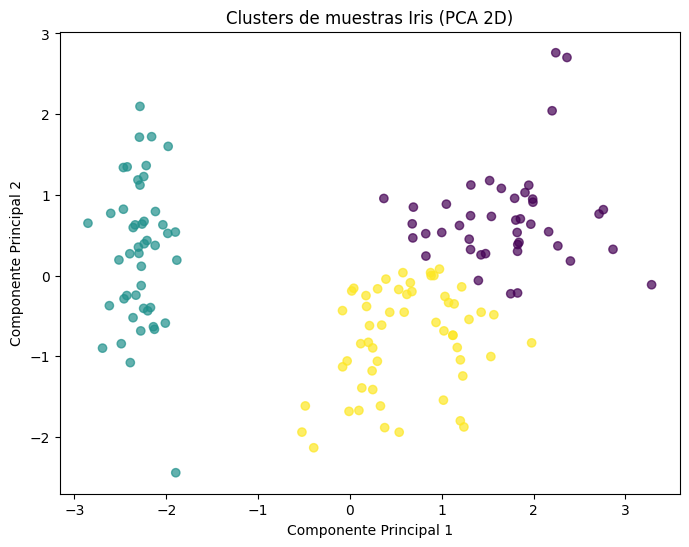

In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df['cluster'] = clusters
print('Cantidad de muestras por cluster:')
print(df['cluster'].value_counts())

# Reducción de dimensionalidad para visualización
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap='viridis', alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Clusters de muestras Iris (PCA 2D)')
plt.show()

### 4. Reducción de dimensionalidad con PCA
Se interpreta y grafica los componentes principales coloreados por cluster.

Varianza explicada por cada componente principal:
[0.72808321 0.22877251]
El primer componente principal representa la mayor variabilidad en las muestras de Iris, el segundo la siguiente mayor fuente de variabilidad.


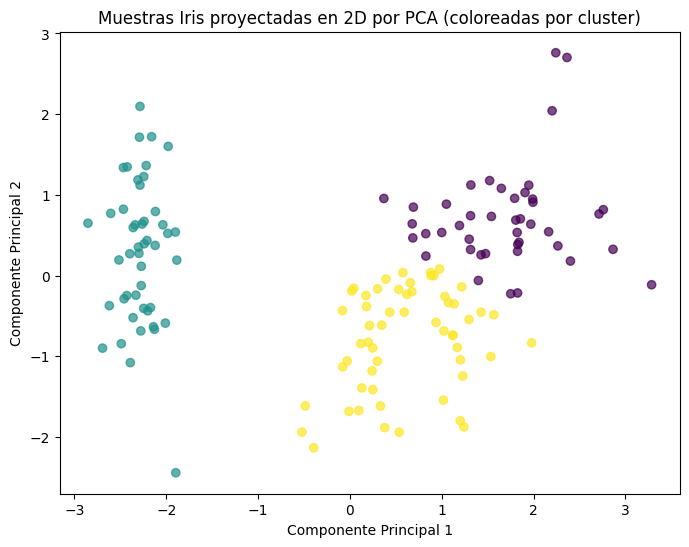

In [4]:
print('Varianza explicada por cada componente principal:')
print(pca.explained_variance_ratio_)

# Breve interpretación
print('El primer componente principal representa la mayor variabilidad en las muestras de Iris, el segundo la siguiente mayor fuente de variabilidad.')

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap='viridis', alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Muestras Iris proyectadas en 2D por PCA (coloreadas por cluster)')
plt.show()

### 5. Detección de anomalías
Se calculan las distancias euclidianas a los centroides y se marcan las 5 muestras más alejadas como anomalías.

In [5]:
# Calcular distancias euclidianas al centroide de su cluster
centroids = kmeans.cluster_centers_
distances = np.linalg.norm(X_scaled - centroids[clusters], axis=1)
df['distancia_centroide'] = distances
# Marcar como anomalía las 5 muestras más alejadas
top_anomalias = df['distancia_centroide'].nlargest(6).index
df['anomalía'] = False
df.loc[top_anomalias, 'anomalía'] = True
print('Muestras marcadas como anomalía:')
display(df[df['anomalía']])

Muestras marcadas como anomalía:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster,distancia_centroide,anomalía
14,5.8,4.0,1.2,0.2,1,1.865361,True
41,4.5,2.3,1.3,0.3,1,2.777629,True
93,5.0,2.3,3.3,1.0,2,1.681584,True
117,7.7,3.8,6.7,2.2,0,2.130603,True
118,7.7,2.6,6.9,2.3,0,1.921461,True
131,7.9,3.8,6.4,2.0,0,2.200851,True


### 6. Reflexión final
¿Qué hallazgos consideras más útiles para el equipo de marketing o investigación? ¿Cómo podrían usar esta segmentación en campañas o estudios personalizados?

- Los clusters identifican grupos de muestras con características similares, permitiendo análisis dirigidos.
- La reducción de dimensionalidad facilita la visualización y comprensión de patrones.
- La detección de anomalías ayuda a identificar muestras con características inusuales, útiles para estudios de calidad o investigación.